# 3. Hipóteses — Thermal Predictor

Hipóteses da Seção 4.2.3 sobre o efeito das configurações de ensaio (`blower_direction`, `housing`, `board_position`, `run_case`, `losses`, `deflector_hole`, `material_coil_support`) na temperatura e na excedência do `active_limit`.

| # | Hipótese | Seria falsa se |
|---|---|---|
| **H1** | O efeito de uma configuração muda de sinal conforme a área: a mesma mudança aquece uma área e resfria outra. Configurações redistribuem calor, não o eliminam. | O efeito tivesse o mesmo sinal em todas as áreas, variando só em magnitude. |
| **H2** | As sete configurações não são independentes. O desenho dos 56 runs as confunde a ponto de `losses` ser redundante com `deflector_hole`. | Cada nível de `losses` aparecesse tanto com `deflector_hole = Open` quanto com `Closed`. |

Duas decisões metodológicas, porque mudam o resultado:

1. A unidade de análise é o run, não a linha. As 4.065 linhas são 56 runs × ~73 sensores, e a configuração é propriedade do run — testar sobre linhas seria pseudo-replicação.
2. O alvo é `temp_delta` (leitura menos a média do próprio sensor), que isola o efeito da configuração da identidade do sensor.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

df = pd.read_csv('../data/dataset_long.csv')

CONFIGS = ['blower_direction', 'housing', 'board_position', 'run_case',
           'losses', 'deflector_hole', 'material_coil_support']
for col in CONFIGS + ['key_area', 'tc_name']:
    df[col] = df[col].astype('string').str.strip()
df['blower_direction'] = df['blower_direction'].str.title()
df['temp'] = pd.to_numeric(df['temp'])

# active_limit tem 2 placeholders de "sem limite": o texto "Monitor (150 C)" e o
# valor 1000 (nenhum limite real passa de 220 C). Ambos viram ausente.
df['limite'] = pd.to_numeric(df['active_limit'], errors='coerce')
df.loc[df['limite'] == 1000, 'limite'] = np.nan
df['excede'] = np.where(df['limite'].isna(), np.nan, (df['temp'] > df['limite']).astype(float))

# Alvo dos testes: quanto o run deixou cada sensor acima/abaixo do que ele costuma marcar.
df['temp_delta'] = df['temp'] - df.groupby('tc_name')['temp'].transform('mean')

# Nivel run x area (1 obs por combinacao) + configuracao, que e propriedade do run.
ra = (df.groupby(['run_id', 'key_area'])
        .agg(delta=('temp_delta', 'mean')).reset_index())
cfg = df.groupby('run_id')[CONFIGS].first()
P = ra.pivot(index='run_id', columns='key_area', values='delta')
AREAS = list(P.columns)

sns.set_theme(style='whitegrid')
FIG_DIR = '../assets/graficos'
os.makedirs(FIG_DIR, exist_ok=True)

print(f'{len(df)} linhas -> {len(ra)} observacoes run x area | {df["run_id"].nunique()} runs '
      f'| {len(AREAS)} areas | excedencia global {df["excede"].mean() * 100:.1f}%')

4065 linhas -> 389 observacoes run x area | 56 runs | 7 areas | excedencia global 8.3%


---

# H1 — O efeito de uma configuração inverte de sinal conforme a área

Nenhuma configuração aquece ou resfria o produto como um todo. Cada mudança redistribui calor: a mesma alteração que resfria uma área aquece outra. Se isso valer, escolher uma configuração é escolher qual área proteger.

In [2]:
CONTRASTES = [
    ('deflector_hole',        'Open',    'Closed'),
    ('blower_direction',      'To Back', 'To Front'),
    ('housing',               'Open',    'Closed'),
    ('material_coil_support', 'Plastic', 'Aluminium'),
    ('board_position',        'Right',   'Center'),
]


def efeito_por_area(config, nivel_a, nivel_b):
    """Diferenca de temp_delta entre dois niveis, area por area. Cada observacao
    e um par (run, area) — nunca uma linha do dataset bruto."""
    saida = []
    for area in AREAS:
        sub = ra[ra['key_area'] == area].merge(cfg[[config]], on='run_id')
        ga = sub.loc[sub[config] == nivel_a, 'delta']
        gb = sub.loc[sub[config] == nivel_b, 'delta']
        if len(ga) < 2 or len(gb) < 2:
            continue
        saida.append({
            'config': f'{config}: {nivel_a} − {nivel_b}', 'key_area': area,
            'n_a': len(ga), 'n_b': len(gb),
            'efeito (C)': round(ga.mean() - gb.mean(), 2),
            'p_welch': stats.ttest_ind(ga, gb, equal_var=False).pvalue,
            'p_mw': stats.mannwhitneyu(ga, gb, alternative='two-sided').pvalue,
        })
    return saida


def benjamini_hochberg(pvals):
    """p ajustado por FDR — sao 35 testes simultaneos."""
    p = np.asarray(pvals, dtype=float)
    n, ordem, ajustado, menor = len(p), np.argsort(pvals), np.empty(len(p)), 1.0
    for rank, idx in enumerate(ordem[::-1]):
        menor = min(menor, p[idx] * n / (n - rank))
        ajustado[idx] = menor
    return ajustado


efeitos = pd.DataFrame([x for c in CONTRASTES for x in efeito_por_area(*c)])
efeitos['p_welch_bh'] = benjamini_hochberg(efeitos['p_welch'])
efeitos['p_mw_bh'] = benjamini_hochberg(efeitos['p_mw'])
efeitos['nominal'] = (efeitos['p_welch'] < 0.05) & (efeitos['p_mw'] < 0.05)
efeitos['robusto'] = (efeitos['p_welch_bh'] < 0.05) & (efeitos['p_mw_bh'] < 0.05)


A matriz abaixo mostra, para os 35 pares área × configuração, quantos °C cada mudança move cada área — vermelho aquece, azul resfria. O que interessa não é uma célula isolada, e sim se vermelho e azul convivem na mesma coluna.

Uma nota de vocabulário, porque a seção usa a palavra duas vezes com sentidos diferentes. Cada célula da matriz é um *contraste simples*: a diferença entre as médias dos dois níveis dentro de uma área. Abrir o `deflector_hole` dá +7,9 °C em `IPC Comp` e −5,1 °C em `Main Vent Sys`. Já o *contraste de interação* é a subtração desses dois, +7,9 − (−5,1) = +13,0 °C, e é ele que testa H1: mede o quanto o efeito difere entre as áreas, e ficaria perto de zero se a configuração empurrasse todas na mesma direção. Ele também é mais preciso — os dois efeitos vêm dos mesmos runs, então o ruído comum se cancela na subtração.

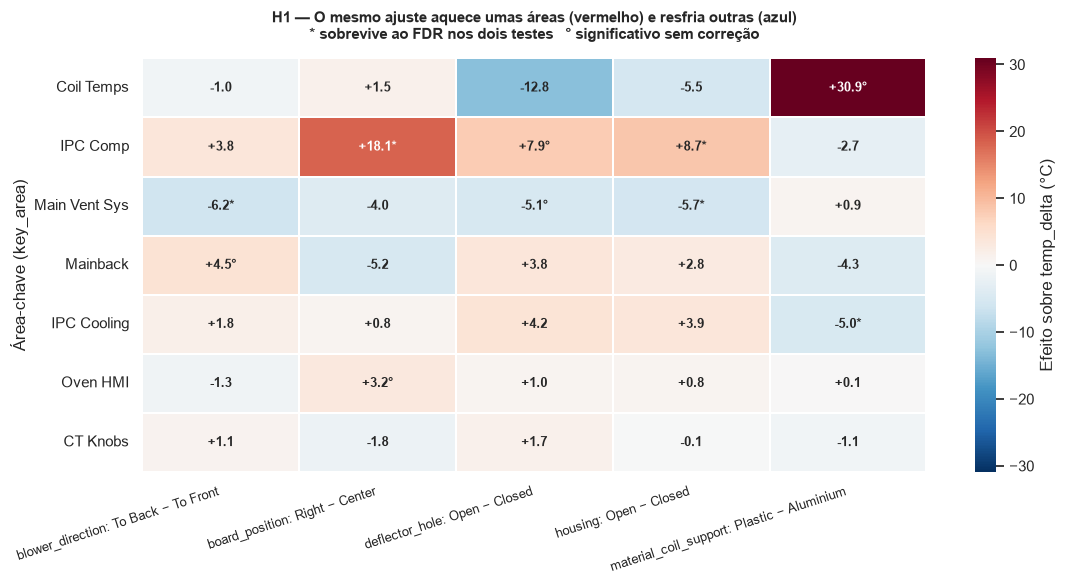

In [3]:
matriz = efeitos.pivot(index='key_area', columns='config', values='efeito (C)')
rob = efeitos.pivot(index='key_area', columns='config', values='robusto')
nom = efeitos.pivot(index='key_area', columns='config', values='nominal')
ordem = matriz.abs().max(axis=1).sort_values(ascending=False).index
matriz, rob, nom = matriz.loc[ordem], rob.loc[ordem], nom.loc[ordem]

anot = matriz.copy().astype(object)
for i in matriz.index:
    for j in matriz.columns:
        v = matriz.loc[i, j]
        anot.loc[i, j] = '' if pd.isna(v) else \
            f'{v:+.1f}' + ('*' if rob.loc[i, j] else ('°' if nom.loc[i, j] else ''))

lim = np.nanmax(np.abs(matriz.to_numpy()))
fig, ax = plt.subplots(figsize=(11.5, 6))
sns.heatmap(matriz, annot=anot, fmt='', cmap='RdBu_r', center=0, vmin=-lim, vmax=lim,
            linewidths=1.2, linecolor='white', ax=ax,
            cbar_kws={'label': 'Efeito sobre temp_delta (°C)'},
            annot_kws={'fontsize': 9.5, 'fontweight': 'bold'})
ax.set_xlabel('')
ax.set_ylabel('Área-chave (key_area)')
ax.set_title('H1 — O mesmo ajuste aquece umas áreas (vermelho) e resfria outras (azul)\n'
             '* sobrevive ao FDR nos dois testes   ° significativo sem correção',
             fontsize=11, fontweight='bold', pad=14)
plt.xticks(rotation=18, ha='right', fontsize=9)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/hip_h1_inversao_por_area.png', dpi=150, bbox_inches='tight')
plt.show()

O sinal alterna dentro de todas as colunas, como H1 prevê. Mas a matriz não testa a hipótese: só 5 dos 35 efeitos sobrevivem à correção para comparações múltiplas — consequência de espalhar a informação por 35 testes, não evidência contra H1. A célula seguinte aplica o contraste de interação, um teste focado por par de áreas.

In [4]:
def contraste_interacao(config, nivel_a, nivel_b, area1, area2, n_perm=10_000, seed=42):
    """Testa se o efeito da config DIFERE entre duas areas.

    H0: o efeito e o mesmo nas duas areas. Sob H0 o rotulo da configuracao e
    permutavel ENTRE RUNS — a permutacao correta, ja que a configuracao e uma
    propriedade do run. Permutar linhas quebraria a estrutura que H0 preserva.
    """
    validos = [r for r in P.index if r in set(cfg.index[cfg[config].isin([nivel_a, nivel_b])])]
    M = P.loc[validos].to_numpy()
    grupo = (cfg.loc[validos, config] == nivel_a).to_numpy()
    i1, i2 = AREAS.index(area1), AREAS.index(area2)

    def contraste(mascara):
        with np.errstate(invalid='ignore'):
            ef = np.nanmean(M[mascara], axis=0) - np.nanmean(M[~mascara], axis=0)
        return ef[i1] - ef[i2]

    obs = contraste(grupo)
    rng = np.random.default_rng(seed)
    nulo = np.array([contraste(rng.permutation(grupo)) for _ in range(n_perm)])
    return obs, (np.abs(nulo) >= abs(obs)).mean(), nulo


PARES = [
    ('deflector_hole', 'Open', 'Closed', 'IPC Comp', 'Main Vent Sys'),
    ('blower_direction', 'To Back', 'To Front', 'Mainback', 'Main Vent Sys'),
    ('housing', 'Open', 'Closed', 'IPC Comp', 'Main Vent Sys'),
    ('material_coil_support', 'Plastic', 'Aluminium', 'Coil Temps', 'Mainback'),
]

nulos = {}
for config, na, nb, a1, a2 in PARES:
    obs, p, nulo = contraste_interacao(config, na, nb, a1, a2)
    nulos[(config, a1, a2)] = (obs, p, nulo)


Cada painel é um dos quatro contrastes de interação. O histograma cinza é a distribuição sob a hipótese nula — o que se obteria se o efeito fosse igual nas duas áreas — construída embaralhando 10.000 vezes o rótulo da configuração entre os runs. A linha vermelha é o valor observado: quanto mais afastada, menor a chance de a inversão ser acaso.

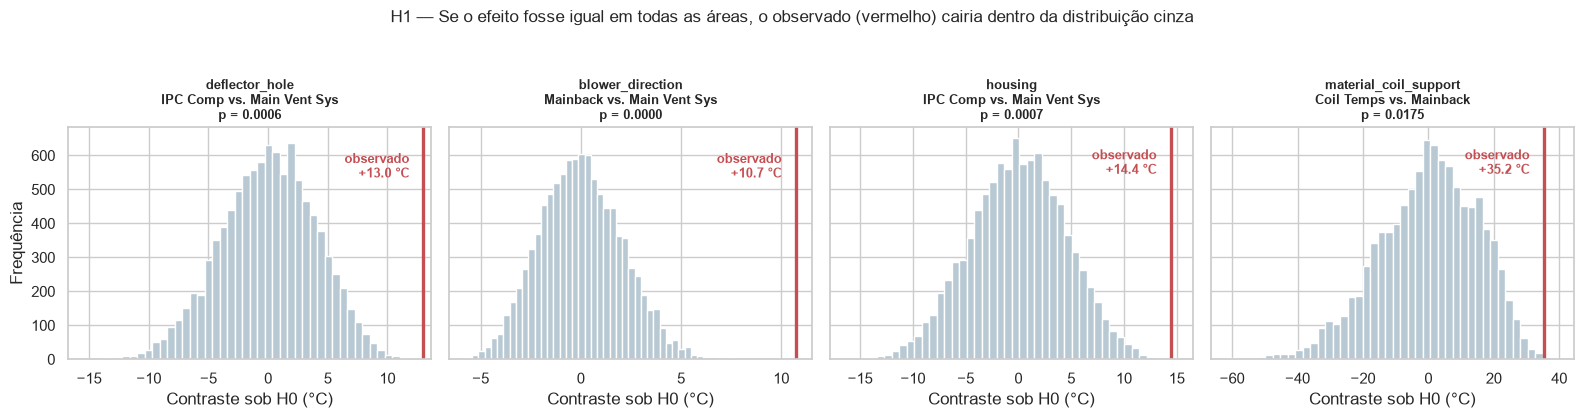

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, (chave, (obs, p, nulo)) in zip(axes, nulos.items()):
    config, a1, a2 = chave
    ax.hist(nulo, bins=44, color='#B8C9D4', edgecolor='white')
    ax.axvline(obs, color='#C44E52', lw=2.4)
    ax.annotate(f'observado\n{obs:+.1f} °C', (obs, ax.get_ylim()[1] * 0.80),
                xytext=(-10, 0), textcoords='offset points', ha='right',
                fontsize=9, color='#C44E52', fontweight='bold')
    ax.set_title(f'{config}\n{a1} vs. {a2}\np = {p:.4f}', fontsize=9.5, fontweight='bold')
    ax.set_xlabel('Contraste sob H0 (°C)')
axes[0].set_ylabel('Frequência')
fig.suptitle('H1 — Se o efeito fosse igual em todas as áreas, o observado (vermelho) '
             'cairia dentro da distribuição cinza', fontsize=12, y=1.04)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/hip_h1_permutacao_interacao.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
# Traducao dos efeitos de temperatura para a metrica de negocio: a taxa de
# excedencia do active_limit. Ficamos so com as areas em que o zero e
# verificavel (limite registrado em >90% das linhas) — nas demais, um zero
# pode ser seguranca OU ausencia de limite, e as duas coisas sao
# indistinguiveis. Isso evita uma tabela cheia de zeros ambiguos.
cob = df.groupby('key_area').agg(linhas=('temp', 'size'), com_limite=('limite', 'count'))
cob['cobertura'] = cob['com_limite'] / cob['linhas']
AREAS_CONFIAVEIS = cob.index[cob['cobertura'] > 0.9].tolist()
EXCLUIDAS = [a for a in cob.index if a not in AREAS_CONFIAVEIS]

risco = []
for config, nivel_a, nivel_b in CONTRASTES[:2]:
    sub = df.merge(cfg[[config]], on='run_id', suffixes=('', '_cfg'))
    col = f'{config}_cfg' if f'{config}_cfg' in sub.columns else config
    piv = (sub[sub[col].isin([nivel_a, nivel_b])]
           .pivot_table(index='key_area', columns=col, values='excede', aggfunc='mean') * 100)
    piv = piv.loc[[a for a in AREAS_CONFIAVEIS if a in piv.index]]
    for area, linha in piv.iterrows():
        if linha[nivel_a] == 0 and linha[nivel_b] == 0:
            continue  # area que nunca excede em nenhum dos dois niveis: nao informa trade-off
        risco.append({
            'configuracao': f'{config}: {nivel_b} -> {nivel_a}', 'area': area,
            'antes (%)': round(linha[nivel_b], 1), 'depois (%)': round(linha[nivel_a], 1),
            'variacao (p.p.)': round(linha[nivel_a] - linha[nivel_b], 1),
        })

risco = pd.DataFrame(risco)
print('Excedencia do active_limit — apenas areas com limite registrado em >90% das linhas')
print(f'(excluidas por zero nao verificavel: {EXCLUIDAS})\n')
for config, bloco in risco.groupby('configuracao'):
    print(f'--- {config} ---')
    print(bloco.drop(columns='configuracao').to_string(index=False), '\n')

Excedencia do active_limit — apenas areas com limite registrado em >90% das linhas
(excluidas por zero nao verificavel: ['IPC Cooling', 'Main Vent Sys'])

--- blower_direction: To Front -> To Back ---
      area  antes (%)  depois (%)  variacao (p.p.)
Coil Temps        8.1         7.1             -1.0
  IPC Comp        7.3        16.2              8.9
  Mainback       10.8        21.9             11.1 

--- deflector_hole: Closed -> Open ---
      area  antes (%)  depois (%)  variacao (p.p.)
Coil Temps        9.8         3.2             -6.6
  IPC Comp        3.4        22.8             19.4
  Mainback       11.1        20.0              8.9 



### Veredito da H1 — confirmada

Os quatro contrastes testados são significativos e todos caem fora da distribuição nula:

| configuração | aquece | resfria | contraste | *p* |
|---|---|---|---|---|
| `deflector_hole = Open` | IPC Comp | Main Vent Sys | +13,0 °C | 0,0006 |
| `blower_direction = To Back` | Mainback | Main Vent Sys | +10,7 °C | < 0,0001 |
| `housing = Open` | IPC Comp | Main Vent Sys | +14,4 °C | 0,0007 |
| `material = Plastic` | Coil Temps | Mainback | +35,2 °C | 0,0175 |

Os efeitos têm direções opostas, não apenas magnitudes diferentes — não é ruído desigual entre áreas.

Em risco, não só em temperatura: abrir o `deflector_hole` leva `IPC Comp` de 3,4% para 22,8% de excedência e, no mesmo movimento, `Coil Temps` de 9,8% para 3,2%. Não há escolha dominante, decide-se qual área proteger. Já `To Back` piora as duas áreas eletrônicas ao mesmo tempo (Mainback 10,8% → 21,9%; IPC Comp 7,3% → 16,2%) sem melhorar nenhuma outra: nem toda configuração é trade-off, algumas são só piores.

O padrão é o de conservação de energia — abrir uma passagem não elimina o calor, o reconduz. `Main Vent Sys` aparece repetidamente como a área que recebe o calor que sai das demais.

Consequência para a Seção 4.2.4: um modelo sem interação `área × configuração` estimaria, para `deflector_hole = Open`, uma média entre +7,9 e −5,1 °C — número que não descreve nenhuma das duas áreas e erra o sinal em pelo menos uma. A predição precisa ser condicionada à área.

Ressalvas:

1. O maior efeito é o menos confiável. `board_position = Right` marca +18,1 °C em `IPC Comp`, mas vem de 3 runs que compartilham todas as demais configurações. O teste responde "esses 3 runs diferem dos outros 53?", não "a posição da placa causa isso?". A H2 mostra por quê.
2. Parte dos zeros de excedência é ausência de dado: `IPC Cooling` tem 76% das leituras sem `active_limit` e `Main Vent Sys`, 42%. Por isso a tabela acima exclui essas áreas — e por isso o resfriamento de `Main Vent Sys` se confirma em temperatura, mas não em excedência.
3. Os pares de áreas foram escolhidos depois de olhar a matriz. O padrão é robusto, mas os *p* não têm a garantia de um teste pré-registrado.

---

# H2 — As configurações não são variáveis independentes

As sete configurações estão confundidas no desenho experimental a ponto de `losses` ser perfeitamente redundante com `deflector_hole`. Se isso valer, os efeitos medidos na H1 são de configurações inteiras, não de variáveis isoladas.

Os 56 runs não vêm de um fatorial planejado, e sim de um histórico de ensaios: cada run respondia a uma pergunta específica (registrada em `reason`), e mudar o housing para investigar um problema tipicamente vinha junto com mudar o deflector e o modo. O esperado é um espaço esparso e correlacionado, possivelmente com pares aliasados.

In [7]:
def v_de_cramer(x, y):
    """Associacao entre categoricas: 0 = independentes, 1 = uma determina a outra."""
    tab = pd.crosstab(x, y)
    if min(tab.shape) < 2:
        return np.nan
    n = tab.to_numpy().sum()
    esperado = np.outer(tab.sum(axis=1), tab.sum(axis=0)) / n
    qui2 = ((tab.to_numpy() - esperado) ** 2 / esperado).sum()
    return np.sqrt(qui2 / (n * (min(tab.shape) - 1)))


V = pd.DataFrame({c1: {c2: (1.0 if c1 == c2 else v_de_cramer(cfg[c1], cfg[c2]))
                       for c2 in CONFIGS} for c1 in CONFIGS})


In [8]:
# Prova direta do aliasing, independente de qualquer premissa estatistica:
# cada categoria de `losses` aparece em quantos valores de `deflector_hole`?
tab = pd.crosstab(cfg['losses'], cfg['deflector_hole'])
tab['valores_de_deflector'] = (tab > 0).sum(axis=1)
tab['runs'] = tab[['Closed', 'Open']].sum(axis=1)
print(tab.sort_values('runs', ascending=False).to_string())

mistas = int((tab['valores_de_deflector'] > 1).sum())
print(f'\nCategorias de `losses` em AMBOS os deflector_hole: {mistas} de {len(tab)}')
print(f'-> `losses` prediz `deflector_hole` com 100% de acerto nos '
      f'{int(cfg["losses"].notna().sum())} runs em que esta preenchida '
      f'({int(cfg["losses"].isna().sum())} runs sem o campo).')

PRINCIPAIS = ['blower_direction', 'housing', 'deflector_hole', 'material_coil_support']
possiveis = int(np.prod([cfg[c].nunique() for c in PRINCIPAIS]))
ocupacao = cfg.groupby(PRINCIPAIS, observed=True).size().sort_values(ascending=False)
print(f'\nEspaco {" x ".join(PRINCIPAIS)}: {len(ocupacao)} de {possiveis} combinacoes '
      f'ocupadas ({len(ocupacao) / possiveis * 100:.0f}%)')
print(f'As 2 maiores concentram {int(ocupacao.head(2).sum())} dos {len(cfg)} runs:')
print(ocupacao.to_string())

deflector_hole                     Closed  Open  valores_de_deflector  runs
losses                                                                     
Simone Losses                           0    15                     1    15
Broil C2 Simone - Front Order           8     0                     1     8
No losses                               5     0                     1     5
Simone Modified - Back Order            4     0                     1     4
Miro - Front Order                      4     0                     1     4
No Losses                               0     3                     1     3
Broil Miro - Front Order                2     0                     1     2
Miro                                    2     0                     1     2
C1 Simone - 240/145/180/180             2     0                     1     2
Broil C2 Simone - 240/145/180/180       1     0                     1     1
Miro Qualitative  - Back Order          1     0                     1     1
Miro Qualita

As três evidências da H2. À esquerda, a associação entre as configurações — quanto mais escura a célula, mais uma variável determina a outra. No centro, cada barra é uma categoria de `losses` colorida pelo `deflector_hole` dos runs: se houvesse independência, as barras seriam bicolores. À direita, quantos runs há em cada combinação efetivamente ensaiada.

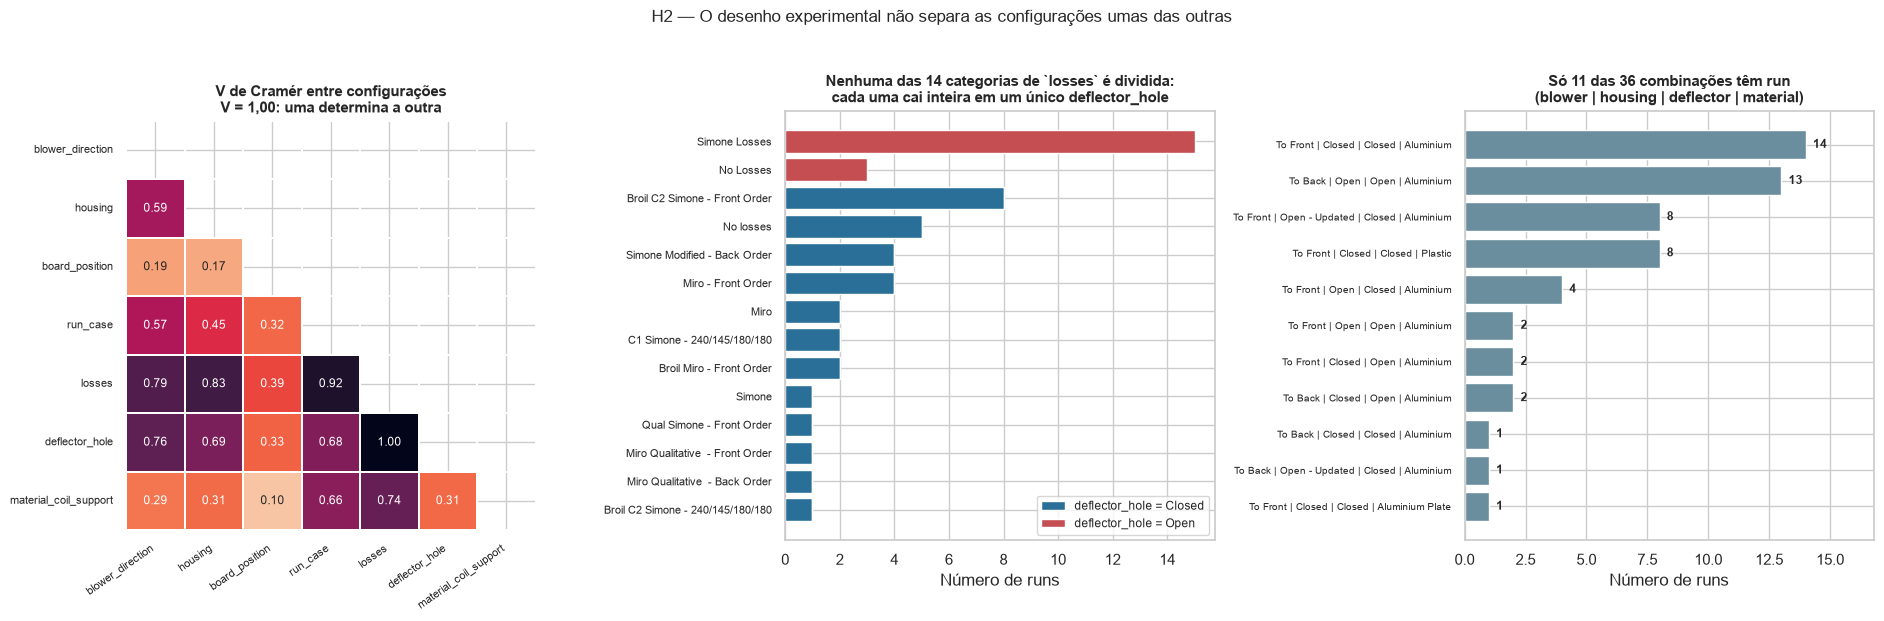

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6), gridspec_kw={'width_ratios': [1, 1.05, 1]})

# 1) Matriz de associacao
ax = axes[0]
sns.heatmap(V.astype(float), mask=np.triu(np.ones_like(V, dtype=bool)), annot=True, fmt='.2f',
            cmap='rocket_r', vmin=0, vmax=1, linewidths=1.2, linecolor='white',
            square=True, ax=ax, cbar=False, annot_kws={'fontsize': 8.5})
ax.set_title('V de Cramér entre configurações\nV = 1,00: uma determina a outra',
             fontsize=10.5, fontweight='bold')
ax.tick_params(labelsize=8)
plt.setp(ax.get_xticklabels(), rotation=35, ha='right')

# 2) Aliasing: nenhuma categoria de losses e dividida
ax = axes[1]
plot_tab = tab[['Closed', 'Open']].sort_values(['Open', 'Closed'])
y = np.arange(len(plot_tab))
ax.barh(y, plot_tab['Closed'], color='#2A6F97', label='deflector_hole = Closed')
ax.barh(y, plot_tab['Open'], left=plot_tab['Closed'], color='#C44E52',
        label='deflector_hole = Open')
ax.set_yticks(y)
ax.set_yticklabels(plot_tab.index, fontsize=8.2)
ax.set_xlabel('Número de runs')
ax.set_title('Nenhuma das 14 categorias de `losses` é dividida:\n'
             'cada uma cai inteira em um único deflector_hole',
             fontsize=10.5, fontweight='bold')
ax.legend(loc='lower right', fontsize=8.5)

# 3) Ocupacao do espaco de configuracoes
ax = axes[2]
oc = ocupacao.sort_values()
ax.barh(np.arange(len(oc)), oc.to_numpy(), color='#6B8E9F')
for i, v in enumerate(oc.to_numpy()):
    ax.text(v + 0.3, i, str(v), va='center', fontsize=8.5, fontweight='bold')
ax.set_yticks(np.arange(len(oc)))
ax.set_yticklabels([' | '.join(map(str, idx)) for idx in oc.index], fontsize=7.2)
ax.set_xlim(0, oc.max() * 1.2)
ax.set_xlabel('Número de runs')
ax.set_title(f'Só {len(ocupacao)} das {possiveis} combinações têm run\n'
             '(blower | housing | deflector | material)', fontsize=10.5, fontweight='bold')

fig.suptitle('H2 — O desenho experimental não separa as configurações umas das outras',
             fontsize=12.5, y=1.02)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/hip_h2_aliasing.png', dpi=150, bbox_inches='tight')
plt.show()

### Veredito da H2 — confirmada

As 14 categorias de `losses` mapeiam cada uma para um único valor de `deflector_hole` (V de Cramér = 1,00). Não é associação forte, é identidade: nenhum run separa as duas variáveis, logo nenhum modelo consegue atribuir um efeito a uma delas em vez da outra.

Uma armadilha de pré-processamento: `"No Losses"` (3 runs, deflector `Open`) e `"No losses"` (5 runs, deflector `Closed`) são o mesmo texto com capitalização diferente, mas correspondem a estados opostos do deflector. Um `.str.title()` de rotina — o mesmo que este notebook aplica em `blower_direction` — fundiria dois grupos distintos e simularia a quebra do aliasing. Padronizar `losses` por capitalização fica proibido enquanto a variável existir.

O confundimento é geral: `run_case`×`losses` 0,92 · `housing`×`losses` 0,83 · `blower_direction`×`deflector_hole` 0,76 (`To Back` vem com deflector `Open` em 15 de 17 runs). E o espaço é esparso: 11 de 36 combinações ocupadas, com 27 dos 56 runs em apenas duas delas — que diferem entre si em blower, housing e deflector ao mesmo tempo. Metade da base é a comparação entre dois blocos de configuração, não entre variáveis.

Isso não contradiz a H1, delimita o que ela mede. Os efeitos são reais e reproduzíveis, mas pertencem a blocos: "abrir o `deflector_hole` aquece IPC Comp em +7,9 °C" significa, com rigor, que os runs com deflector aberto — que são também, majoritariamente, os de housing aberto e blower para trás — apresentam IPC Comp 7,9 °C mais quente. A base identifica configurações de risco, não qual parafuso é responsável.

Decisões para a Seção 4.2.4:

- `losses` sai do modelo: nenhuma informação além de `deflector_hole`, e 14 categorias esparsas. `board_position` sai por confundimento total, o que resolve a ressalva 1 da H1.
- Modelos de árvore distribuem crédito arbitrariamente entre variáveis aliasadas. Esse ranking de importância não pode ser apresentado ao parceiro como evidência de causa.
- Próximos ensaios: priorizar runs que quebrem os aliases — `deflector_hole` variando dentro de um mesmo perfil de `losses`, e `board_position = Right` fora do bloco `Broil Qualitative` + `Simone Losses` + deflector `Open`.

Ressalva: o V de Cramér é enviesado para cima com muitas categorias e poucas observações. Por isso o argumento central não repousa sobre o V, e sim sobre a contagem direta da tabela de contingência.